# 01 · EDA do VLibrasBD

**Onde estamos no ML:** esta é a etapa de *entendimento dos dados* do entregável 2. Aqui ainda não há modelo; o que descobrimos define a tarefa (T1: **manter ou descartar** cada palavra) e as decisões de preparação do notebook 02.

| Etapa | Tipo |
| --- | --- |
| Corpus VLibrasBD (127 mil pares português → glosa, feitos por intérpretes) | dado externo, base do ML |
| Leitura, ingestão com hash, Postgres | infraestrutura (sem ML) |
| Rótulos `MANTER`/`DESCARTAR` | regra de alinhamento que gera os exemplos supervisionados |
| Lema, classe gramatical (spaCy) | extração de atributos (sem decisão) |
| **Decidir quais palavras viram sinal** | **ML nosso, treinado nas fases 3 a 6** |

Fonte: VLibrasBD (`pt-br2libras-gloss`), Mendeley Data, DOI 10.17632/ryj88ckjww.2, CC BY-SA 4.0. Créditos aos autores (Lima et al., 2025, *Data in Brief*).

In [1]:
import json, re, sys
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from textgloss import config, corpus
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
palavras = pd.read_parquet(config.PROCESSED_DIR / "palavras.parquet")
frases = pd.read_parquet(config.PROCESSED_DIR / "frases.parquet")
palavras["rotulo_nome"] = palavras["rotulo"].map({1: "MANTER", 0: "DESCARTAR"})

## 1. Tamanho do corpus e das frases
O artigo do corpus dá em média 12,83 palavras por frase e 7,61 sinais por glosa; conferimos.

In [2]:
frases["n_palavras"] = frases["texto"].str.split().str.len()
frases["n_sinais"] = frases["glosa"].map(lambda g: corpus.gloss_marks(g)["n_sinais"])
resumo = frases.groupby("governo")[["n_palavras", "n_sinais"]].agg(["mean", "median", "max"]).round(2)
resumo.index = resumo.index.map({False: "geral", True: "governo"})
print(f"{len(frases):,} pares após a limpeza")
print(f"média geral: {frases.n_palavras.mean():.2f} palavras e {frases.n_sinais.mean():.2f} sinais por frase")
resumo

127,320 pares após a limpeza
média geral: 12.73 palavras e 7.61 sinais por frase


n_palavras             n_sinais            
              mean median  max     mean median  max
governo                                            
geral        11.21    5.0  257     6.63    3.0  157
governo      14.74   11.0  262     8.90    7.0  128

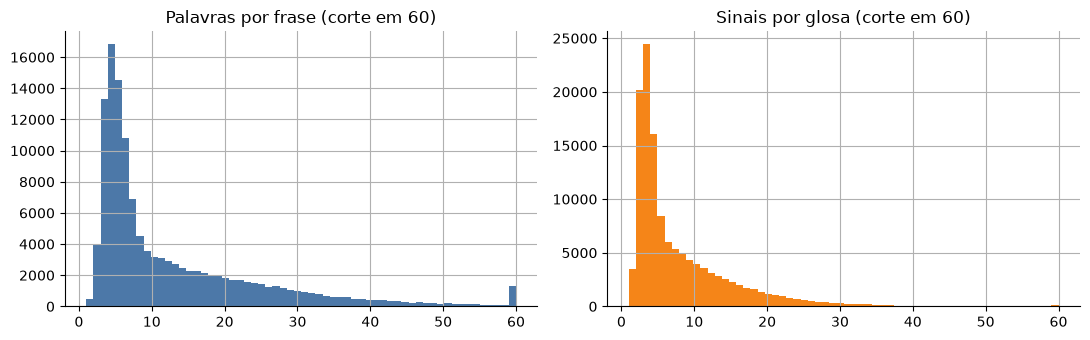

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
frases["n_palavras"].clip(upper=60).hist(bins=60, ax=ax[0], color="#4c78a8"); ax[0].set_title("Palavras por frase (corte em 60)")
frases["n_sinais"].clip(upper=60).hist(bins=60, ax=ax[1], color="#f58518"); ax[1].set_title("Sinais por glosa (corte em 60)")
plt.tight_layout()

**Leitura:** as glosas são bem mais curtas que as frases: os intérpretes descartam e condensam bastante. É essa diferença que o classificador vai tentar prever palavra por palavra.

## 2. Distribuição dos rótulos
Cada palavra recebeu `MANTER` se seu lema ou forma escrita aparece na glosa, senão `DESCARTAR`.

rotulo_nome
MANTER       847748
DESCARTAR    767517

proporção MANTER: 52.5%


(array([0, 1]), [Text(0, 0, 'MANTER'), Text(1, 0, 'DESCARTAR')])

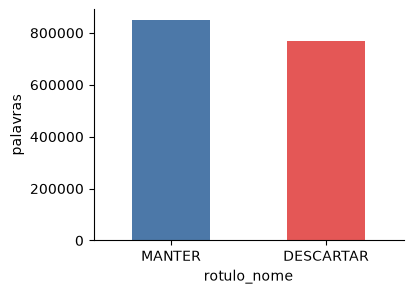

In [4]:
dist = palavras["rotulo_nome"].value_counts()
print(dist.to_string()); print(f"\nproporção MANTER: {palavras.rotulo.mean():.1%}")
dist.plot.bar(color=["#4c78a8", "#e45756"], figsize=(4, 3)); plt.ylabel("palavras"); plt.xticks(rotation=0)

**Leitura:** se as classes estiverem razoavelmente equilibradas, não é um caso de 99% contra 1%. Mesmo assim usaremos **F1-macro** como métrica principal, para que errar a classe menor pese igual, e `class_weight="balanced"` no baseline.

## 3. Descarte por classe gramatical
O que os intérpretes mantêm ou descartam, por UPOS. Se o ML vale a pena, esse padrão tem que existir.

,taxa_manter,n
upos,,
AUX,0.039,54440
SYM,0.064,423
ADP,0.071,301375
CCONJ,0.101,55414
DET,0.126,149828
SCONJ,0.133,33122
INTJ,0.232,393
PUNCT,0.356,205
PRON,0.501,70227


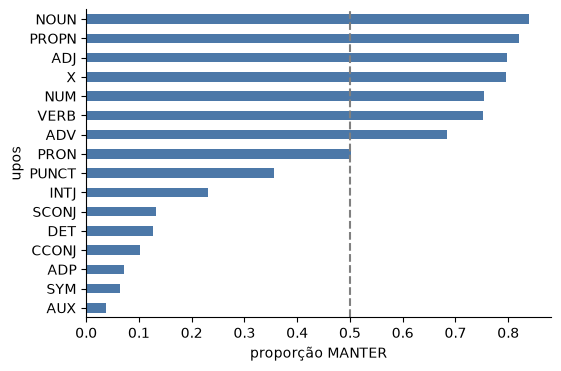

In [5]:
por_upos = palavras.groupby("upos")["rotulo"].agg(taxa_manter="mean", n="size").sort_values("taxa_manter")
por_upos = por_upos[por_upos.n >= 200]
ax = por_upos["taxa_manter"].plot.barh(figsize=(6, 4), color="#4c78a8"); ax.set_xlabel("proporção MANTER"); ax.axvline(0.5, color="gray", ls="--")
por_upos.round(3)

**Leitura:** preposições, auxiliares, conjunções e determinantes tendem a ser descartados; substantivos, adjetivos e verbos, mantidos. Os intermediários (pronomes, advérbios, numerais) são onde o contexto importa, e é onde um modelo pode superar uma lista fixa.

## 4. Palavras mais mantidas e mais descartadas

In [6]:
freq = palavras.groupby("lema")["rotulo"].agg(n="size", taxa_manter="mean")
frequentes = freq[freq.n >= 500].sort_values("taxa_manter")
print("MAIS DESCARTADAS (lemas com ≥500 ocorrências)"); print(frequentes.head(15).round(3).to_string())
print("\nMAIS MANTIDAS"); print(frequentes.tail(15).round(3).to_string())

MAIS DESCARTADAS (lemas com ≥500 ocorrências)
             n  taxa_manter
lema                       
em o     27995        0.002
por o     8687        0.002
em       21132        0.003
para     20871        0.004
o        99125        0.006
pois       502        0.006
tão        573        0.007
a        10591        0.008
estar    11716        0.008
te         658        0.008
ser      38757        0.008
preciso    505        0.008
a o      16070        0.009
e/ou       511        0.010
nº        1086        0.017

MAIS MANTIDAS
                   n  taxa_manter
lema                             
rio              895        0.994
graduação        912        0.995
maria            716        0.996
protocolo        719        0.996
mês              511        0.996
benefício        529        0.996
oficial          656        0.997
ministério       798        0.997
formulário      1224        0.998
portal           891        0.999
consultar       1022        0.999
edital          1066 

### Palavras ambíguas
Lemas frequentes que ora são mantidos e ora descartados são os casos em que a lista fixa erra e o contexto (classe gramatical, vizinhos) deve ajudar.

In [7]:
ambiguas = freq[(freq.n >= 500) & freq.taxa_manter.between(0.25, 0.75)].sort_values("n", ascending=False)
print(f"{len(ambiguas)} lemas frequentes são ambíguos (25% a 75% MANTER)"); ambiguas.head(15).round(3)

69 lemas frequentes são ambíguos (25% a 75% MANTER)


,n,taxa_manter
lema,,
eu,11222,0.640
ou,10869,0.361
seu,10755,0.491
ter,8640,0.699
como,6743,0.401
mais,5837,0.666
ele,5592,0.736
ir,3756,0.343
solicitar,3173,0.454


## 5. Comparação com a lista fixa atual (`FUNCTION_WORDS`)
A API hoje descarta as palavras dessa lista. Este é o **ponto de partida sem ML** que o modelo precisa superar.

In [8]:
src = (ROOT / "api" / "app" / "text_to_gloss.py").read_text(encoding="utf-8")
bloco = re.search(r"FUNCTION_WORDS = frozenset\((.*?)\)\s*\n\n", src, re.S).group(1)
lista = set()
for texto in re.findall(r'"([^"]+)"', bloco):
    lista |= {corpus.slug(w) for w in texto.split()}
palavras["na_lista"] = palavras["palavra"].map(corpus.slug).isin(lista)
palavras["pred_lista"] = (~palavras["na_lista"]).astype(int)
from sklearn.metrics import classification_report, f1_score
print(f"{len(lista)} palavras na lista fixa\n")
print(classification_report(palavras.rotulo, palavras.pred_lista, target_names=["DESCARTAR", "MANTER"], digits=3))

95 palavras na lista fixa



              precision    recall  f1-score   support

   DESCARTAR      0.890     0.723     0.798    767517
      MANTER      0.785     0.919     0.847    847748

    accuracy                          0.826   1615265
   macro avg      0.838     0.821     0.822   1615265
weighted avg      0.835     0.826     0.824   1615265



**Leitura:** esta é a linha de base sem ML medida no corpus inteiro (a medição oficial será só no conjunto de teste, na fase 3). Veja quais palavras da lista os intérpretes na verdade mantiveram:

In [9]:
erros = palavras[(palavras.na_lista) & (palavras.rotulo == 1)].groupby("lema").size().sort_values(ascending=False).head(12)
print("Palavras da lista fixa que os intérpretes MANTIVERAM (mais frequentes):"); print(erros.to_string())

Palavras da lista fixa que os intérpretes MANTIVERAM (mais frequentes):
lema
você      7107
eu        6771
seu       5282
de        4914
de o      4706
que       4605
ele       4116
ou        3919
como      2701
sobre     2209
também    2071
meu       1995


## 6. Marcas da notação das glosas
Conta homônimos (`&`), negação incorporada (`NÃO_`), intensidade (`(+)`/`(-)`), direcionais e tipo de frase. Decide a viabilidade de T2 e T3.

In [10]:
marcas = pd.DataFrame([corpus.gloss_marks(g) for g in frases["glosa"]])
resumo = marcas.drop(columns=["n_sinais", "tipo_frase"]).mean().mul(100).round(2).rename("% das frases")
print(resumo.to_string()); print(); print(marcas["tipo_frase"].value_counts().to_string())

tem_homonimo       55.92
tem_negacao        10.21
tem_intensidade     1.49
tem_direcional      5.44

tipo_frase
[PONTO]           93087
nenhum            25129
[INTERROGAÇÃO]     8002
[EXCLAMAÇÃO]       1102


In [11]:
sentidos = {}
for g in frases["glosa"]:
    for t in g.split():
        if "&" in t:
            sentidos.setdefault(t.split("&")[0], Counter())[t] += 1
viaveis = {k: v for k, v in sentidos.items() if len(v) >= 2 and sorted(v.values())[-2] >= 30}
print(f"{len(sentidos)} lemas com marca `&`; {len(viaveis)} têm ≥2 sentidos com ≥30 exemplos cada (viáveis para T2)")
list(viaveis)[:15]

2408 lemas com marca `&`; 189 têm ≥2 sentidos com ≥30 exemplos cada (viáveis para T2)


['DOAR',
 'OBRA',
 'PODER',
 'CURSO',
 'CONTA',
 'ANO',
 'BASE',
 'CONSULTAR',
 'SELEÇÃO',
 'ÓRGÃO',
 'PÚBLICO',
 'SOBRE',
 'DEVER',
 'ORGANIZAÇÃO',
 'AÇÃO']

## 7. Domínio geral × governo
A coluna `is_government_source` permite testar generalização fora do domínio (fase 6).

In [12]:
g = palavras.groupby("governo").agg(palavras=("rotulo", "size"), manter=("rotulo", "mean"))
g.index = g.index.map({False: "geral", True: "governo"}); print(g.round(3))
dom = {d: set(palavras.loc[palavras.governo == d, "lema"]) for d in (False, True)}
inter = len(dom[False] & dom[True]); uniao = len(dom[False] | dom[True])
print(f"\nvocabulário (lemas): geral {len(dom[False]):,}, governo {len(dom[True]):,}, sobreposição {inter/uniao:.1%}")

         palavras  manter
governo                  
geral      809327   0.521
governo    805938   0.528

vocabulário (lemas): geral 47,210, governo 27,657, sobreposição 20.5%


## 8. Cobertura do dicionário do VLibras
Quantos dos sinais mais frequentes do corpus o player consegue tocar (`python -m textgloss.coverage`). Define se o vocabulário do Sinaliza pode crescer além dos 210 sinais atuais.

In [13]:
cob_path = config.PROCESSED_DIR / "cobertura_dicionario.csv"
if cob_path.exists():
    cob = pd.read_csv(cob_path)
    pct_sinais = cob.no_dicionario.mean(); pct_ocorr = cob.loc[cob.no_dicionario, "ocorrencias"].sum() / cob.ocorrencias.sum()
    print(f"{pct_sinais:.1%} dos {len(cob)} sinais mais frequentes existem no dicionário ({pct_ocorr:.1%} das ocorrências)")
    print("\nMais frequentes AUSENTES do dicionário:"); print(cob[~cob.no_dicionario].head(12).to_string(index=False))
else:
    print("Rode `python -m textgloss.coverage` para gerar a tabela de cobertura.")

95.3% dos 1500 sinais mais frequentes existem no dicionário (96.0% das ocorrências)

Mais frequentes AUSENTES do dicionário:
    sinal  ocorrencias  no_dicionario
      TOM        10653          False
    MARIA          702          False
     MARY          632          False
   PEDIDO          589          False
       10          493          False
       30          481          False
  INDICAR          456          False
  PESSOAL          428          False
       19          380          False
       20          373          False
HISTÓRICO          366          False
 CONSELHO          360          False


**Observação sobre o domínio geral:** boa parte das frases do domínio geral vem de coleções de exemplos (por isso `TOM` e `MARIA` aparecem tanto). Isso torna o vocabulário do domínio geral menos diverso do que parece e reforça testar fora do domínio (geral → governo) na fase 6.

## Conclusões da EDA

Números calculados na execução (a célula abaixo imprime o resumo).

In [14]:
print(f"""
1. O corpus tem {len(frases):,} pares e {len(palavras):,} palavras (pontuação fora).
2. {palavras.rotulo.mean():.0%} das palavras são MANTIDAS; F1-macro continua a métrica principal.
3. A classe gramatical separa os extremos, mas {len(ambiguas)} lemas frequentes são ambíguos: é onde o ML pode ganhar da lista fixa.
4. A lista fixa atual tem F1-macro de {f1_score(palavras.rotulo, palavras.pred_lista, average="macro"):.3f} no corpus: o modelo precisa superar esse número no teste.
5. T2 (homônimos): {len(viaveis)} lemas candidatos; T3 depende das contagens da seção 6.
""")


1. O corpus tem 127,320 pares e 1,615,265 palavras (pontuação fora).
2. 52% das palavras são MANTIDAS; F1-macro continua a métrica principal.
3. A classe gramatical separa os extremos, mas 69 lemas frequentes são ambíguos: é onde o ML pode ganhar da lista fixa.
4. A lista fixa atual tem F1-macro de 0.822 no corpus: o modelo precisa superar esse número no teste.
5. T2 (homônimos): 189 lemas candidatos; T3 depende das contagens da seção 6.

